# Figure 2: Package landscape

Compare 2025 Europe PMC counts across the 30 registry packages and calculate each package's 2020-to-2025 fold change. The figure marks changes from fewer than 20 starting papers as fragile.

## Inputs

| Committed file | Contents | Producer |
| --- | --- | --- |
| `config/tools.yml` | Curated aliases, categories and query context | Manual registry, read by `python -m census.build.build_dataset` |
| `data/processed/tools.csv` | Package names, categories, scope and aggregate flags | `python -m census.build.build_dataset` |
| `data/processed/literature_yearly.csv` | Yearly package mention counts by source | `python -m census.build.build_dataset` |
| `data/processed/corpus_yearly.csv` | Yearly indexed full-text microscopy denominator | `python -m census.build.build_dataset` |

Input paths are relative to the repository root. The closing check also reads `../MANUSCRIPT/FIGURES/Figure2__landscape.png` when present. The manuscript image is optional and stays outside a public clone.

## Set up offline analysis

Locate the repository in either layout, load the package registry and import the shared publication renderer. This cell makes no API requests.

In [1]:
from pathlib import Path
from io import BytesIO
from tempfile import TemporaryDirectory
import sys
import hashlib

import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
SCRIPTS_DIR = next(p for p in (cwd, *cwd.parents) if (p / 'census' / '_registry.py').is_file())
REPO_ROOT = SCRIPTS_DIR.parent
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import fig2_landscape as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame


## Registry and query construction

`_registry.load_registry()` supplies the aliases, scope, aggregate flag, and shared microscopy context. `build_boolean_query()` assembles the alias clause and context, yearly counts add the year restriction.

In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['imagej', 'qupath', 'cellprofiler', 'napari']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
2,napari,napari,"""napari"" AND ((microscopy OR microscope) AND H..."
3,cellprofiler,CellProfiler,"""CellProfiler"" AND ((microscopy OR microscope)..."
4,qupath,QuPath,"""QuPath"" AND ((microscopy OR microscope) AND H..."


## Read panel inputs

Load the committed data for the calculations below. The three columns show package labels, 2025 mention counts and 2020-to-2025 fold changes. We check ranks, small starting counts and aggregate membership.

In [3]:
inspect_processed('tools.csv')
literature_all = inspect_processed('literature_yearly.csv')
inspect_processed('corpus_yearly.csv')

tools.csv: shape=(30, 7)


,tool_id,name,category,implies_dl,in_aggregate,scope,homepage
0,jupyter,Jupyter notebooks,notebook,False,False,core,https://jupyter.org
1,imagej,ImageJ / Fiji,general-platform,False,True,core,https://imagej.net
2,napari,napari,general-platform,False,True,core,https://napari.org
3,cellprofiler,CellProfiler,general-platform,False,True,core,https://cellprofiler.org
4,qupath,QuPath,general-platform,False,True,core,https://qupath.github.io


literature_yearly.csv: shape=(960, 4)


,source,tool_id,year,count
0,openalex,jupyter,2010,0
1,openalex,jupyter,2011,0
2,openalex,jupyter,2012,0
3,openalex,jupyter,2013,0
4,openalex,jupyter,2014,0


corpus_yearly.csv: shape=(16, 2)


,year,microscopy_papers
0,2010,42806
1,2011,49532
2,2012,58343
3,2013,66112
4,2014,70986


,year,microscopy_papers
0,2010,42806
1,2011,49532
2,2012,58343
3,2013,66112
4,2014,70986
5,2015,78337
6,2016,84586
7,2017,94060
8,2018,100986
9,2019,112489


## Reconstruct panel quantities

The three columns show package labels, 2025 mention counts and 2020-to-2025 fold changes. We check ranks, small starting counts and aggregate membership.

In [4]:
lit = fs.europepmc_yearly()
wide = lit.pivot(index='tool_id', columns='year', values='count').fillna(0)
landscape = registry_table.set_index('tool_id')[['name', 'category', 'scope', 'in_aggregate']].join(wide)
landscape['count_2020'] = landscape[2020]
landscape['count_2025'] = landscape[2025]
landscape['fold_change'] = landscape['count_2025'].div(landscape['count_2020'].replace(0, np.nan))
landscape['fragile_base'] = landscape['count_2020'] < 20
ranked = landscape.sort_values('count_2025', ascending=False)
print(f'Ranked table shape: {ranked.shape}')
display(ranked[['name', 'category', 'scope', 'count_2020', 'count_2025', 'fold_change', 'fragile_base']].head(12))

analysis = fs.analysis_tools()
ranked_analysis = landscape.loc[analysis].sort_values('count_2025', ascending=False)
next_tool = ranked_analysis.iloc[1]
ratio = ranked_analysis.iloc[0]['count_2025'] / next_tool['count_2025']
print('ImageJ/Fiji has {:.1f} times the 2025 matches of {}.'.format(ratio, next_tool['name']))
shares = fs.share_of_total('analysis')
display(shares.loc[(shares.tool_id.eq('imagej')) & shares.year.isin([2010, 2020, 2025]), ['tool_id', 'year', 'share']])

Ranked table shape: (30, 24)


,name,category,scope,count_2020,count_2025,fold_change,fragile_base
tool_id,,,,,,,
imagej,ImageJ / Fiji,general-platform,core,29768,49255,1.654629,False
matlab,MATLAB,commercial,core,6136,7331,1.194752,False
zen,ZEN,acquisition-suite,counts,2557,3859,1.509190,False
nis,NIS-Elements,acquisition-suite,counts,2643,3195,1.208854,False
lasx,LAS X,acquisition-suite,counts,1856,2761,1.487608,False
imaris,Imaris,commercial,core,1961,2744,1.399286,False
qupath,QuPath,general-platform,core,159,1625,10.220126,False
cellsens,cellSens,acquisition-suite,counts,992,1352,1.362903,False
cellprofiler,CellProfiler,general-platform,core,544,1032,1.897059,False


ImageJ/Fiji has 18.0 times the 2025 matches of Imaris.


,tool_id,year,share
16,imagej,2010,79.871406
26,imagej,2020,85.300017
31,imagej,2025,82.135472


## Rebuilding from scratch

All default cells run offline from the committed inputs above. Source collectors need network access when their raw API caches are absent. `python -m census.build.build_dataset` collects counts and snapshots, the specialised producer modules listed under Inputs rebuild their own derived tables. Snapshots retain their original collection date.

To restore sampled titles and abstracts, run `python release/refetch_identifiers.py` with network access. The refetched corpus supports vocabulary classification and research-area calculations. A public clone omits that corpus and the raw response caches. These notebooks display derived data and never fetch records during execution.

## Render all panels

Build `Figure2__landscape` with the shared 300 dpi publication style. Save PNG, PDF and SVG in a temporary directory and retain the full-size PNG pixels for the closing check. Display a scaled preview.

wrote Figure2__landscape.png/.pdf/.svg
Figure2__landscape: 1668 x 1264 pixels


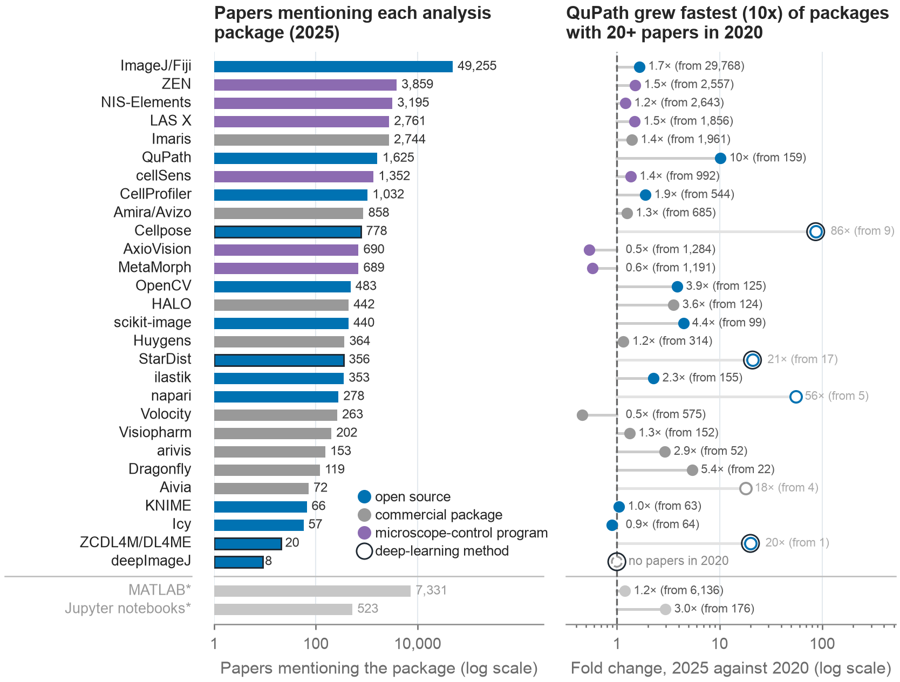

In [5]:
OUTPUT_STEM = 'Figure2__landscape'
fig = figure.build_figure()
with TemporaryDirectory(prefix='notebook-render-') as output_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=output_dir)
    png_bytes = (Path(output_dir) / (OUTPUT_STEM + '.png')).read_bytes()
rendered_pixels = np.asarray(PILImage.open(BytesIO(png_bytes)).convert('RGBA'))
print(f'{OUTPUT_STEM}: {rendered_pixels.shape[1]} x {rendered_pixels.shape[0]} pixels')
preview = PILImage.open(BytesIO(png_bytes))
preview.thumbnail((900, 900))
preview_bytes = BytesIO()
preview.save(preview_bytes, format='PNG')
display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')


## Check against the manuscript

Assert exact pixel equality, including image dimensions and every panel, when the manuscript PNG exists. A public clone prints a skip note for that comparison and still checks that rendering produced pixels. The pixel hash supports comparisons across runs.

In [6]:
assert rendered_pixels.size > 0
reference = REPO_ROOT / 'MANUSCRIPT' / 'FIGURES' / (OUTPUT_STEM + '.png')
if reference.is_file():
    expected_pixels = np.asarray(PILImage.open(reference).convert('RGBA'))
    assert rendered_pixels.shape == expected_pixels.shape, 'Manuscript image dimensions differ'
    np.testing.assert_array_equal(rendered_pixels, expected_pixels)
    print(f'{OUTPUT_STEM}: identical to manuscript PNG (all pixels, all panels)')
else:
    print(f'{OUTPUT_STEM}: manuscript comparison skipped; manuscript PNG is absent in this clone')
print('Rendered pixel SHA-256:', hashlib.sha256(rendered_pixels.tobytes()).hexdigest())


Figure2__landscape: identical to manuscript PNG (all pixels, all panels)
Rendered pixel SHA-256: 75048a51d1f4f60864d3b956a1e12bd6edc3cfe01a13047482d030b92eff12dd
